In [1]:
!pip -q install lightgbm shap pyyaml

from google.colab import drive
drive.mount('/content/drive')

import json, yaml, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.metrics import roc_auc_score

PROJECT_DIR = "/content/drive/MyDrive/fintech_theme3"
DATA_DIR = f"{PROJECT_DIR}/data"

train = pd.read_csv(f"{DATA_DIR}/train_fe.csv", parse_dates=["Date"])
valid = pd.read_csv(f"{DATA_DIR}/valid_fe.csv", parse_dates=["Date"])
test  = pd.read_csv(f"{DATA_DIR}/test_fe.csv",  parse_dates=["Date"])
px    = pd.read_csv(f"{DATA_DIR}/prices.csv",   parse_dates=["Date"])

config = yaml.safe_load(open(f"{PROJECT_DIR}/config.yaml"))
F = config["features"]
best_model = joblib.load(f"{PROJECT_DIR}/model_lgbm.pkl")
print("Модель загружена, признаков:", len(F))

Mounted at /content/drive
Модель загружена, признаков: 21


In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# Базовая модель с параметрами этапа 2 — для сравнения на test
logreg = make_pipeline(
    SimpleImputer(strategy="median"), StandardScaler(),
    LogisticRegression(C=0.0001, max_iter=1000, class_weight="balanced", random_state=42),
).fit(train[F], train["target"])

for d in (train, valid, test):
    d["p"] = best_model.predict_proba(d[F])[:, 1]

auc_lgb = roc_auc_score(test["target"], test["p"])
auc_lr  = roc_auc_score(test["target"], logreg.predict_proba(test[F])[:, 1])

test_metrics = pd.DataFrame({
    "Логистическая регрессия": {"ROC-AUC": auc_lr,  "Gini": 2*auc_lr - 1},
    "LightGBM":                {"ROC-AUC": auc_lgb, "Gini": 2*auc_lgb - 1},
}).T.round(4)
display(test_metrics)
test_metrics.to_csv(f"{PROJECT_DIR}/test_metrics.csv")

,ROC-AUC,Gini
Логистическая регрессия,0.4851,-0.0298
LightGBM,0.5015,0.0031


In [11]:
# Доходность каждой акции с закрытия дня t до закрытия t+1
px = px.sort_values(["Ticker", "Date"])
px["r_next"] = px.groupby("Ticker")["Close"].shift(-1) / px["Close"] - 1
rets = px[["Date", "Ticker", "r_next"]]

def backtest(pred, thr, step=5, fee=0.001):
    """Каждые 5 торговых дней (горизонт прогноза) покупаем акции с p > thr.
    Каждой акции — 1/10 капитала, остальное в деньгах. Комиссия 0.1% от оборота."""
    df = pred[["Date", "Ticker", "p"]].merge(rets, on=["Date", "Ticker"])
    sig = df.pivot(index="Date", columns="Ticker", values="p")
    ret = df.pivot(index="Date", columns="Ticker", values="r_next").fillna(0)

    pos = (sig > thr).astype(float)
    rebalance_days = sig.index[::step]
    pos.loc[~pos.index.isin(rebalance_days)] = np.nan
    pos = pos.ffill()                       # держим позицию до следующей ребалансировки
    w = pos / pos.shape[1]

    turnover = w.diff().abs().sum(axis=1)
    turnover.iloc[0] = w.iloc[0].sum()      # первая покупка
    strat = (w * ret).sum(axis=1) - fee * turnover

    bh = ret.mean(axis=1)                   # «купи и держи» все 10 акций поровну
    bh.iloc[0] -= fee
    return strat, bh, pos

def perf(r):
    eq = (1 + r).cumprod()
    return {
        "Доходность за период": eq.iloc[-1] - 1,
        "Годовая доходность": eq.iloc[-1] ** (252 / len(r)) - 1,
        "Sharpe": r.mean() / r.std() * np.sqrt(252),
        "Макс. просадка": (eq / eq.cummax() - 1).min(),
    }

# Кандидаты порога — квантили прогнозов на validation
thresholds = np.unique(np.round(np.quantile(valid["p"], [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]), 4))
rows = []
for thr in thresholds:
    s, b, pos = backtest(valid, thr)
    rows.append({"Порог": thr, "Доля времени в позиции": pos.mean().mean(), **perf(s)})
thr_table = pd.DataFrame(rows)
display(thr_table.round(4))

best_thr = thr_table.loc[thr_table["Sharpe"].idxmax(), "Порог"]
print("Выбранный порог (по Sharpe на validation):", best_thr)

,Порог,Доля времени в позиции,Доходность за период,Годовая доходность,Sharpe,Макс. просадка
0,0.5637,0.7884,0.5863,0.3105,2.4961,-0.0765
1,0.5673,0.7035,0.5753,0.3052,2.6122,-0.0815
2,0.5706,0.6023,0.5482,0.2919,2.7554,-0.0660
3,0.5735,0.4953,0.4474,0.2420,2.5237,-0.0623
4,0.5771,0.4023,0.4368,0.2367,2.6097,-0.0547
5,0.5815,0.3023,0.4253,0.2308,2.8206,-0.0492
6,0.5866,0.1942,0.2917,0.1618,2.6066,-0.0357


Выбранный порог (по Sharpe на validation): 0.5815


In [12]:
   s_v, bh_v, _ = backtest(valid, best_thr)
   display(pd.DataFrame({"Стратегия": perf(s_v), "Купи и держи": perf(bh_v)}).T.round(4))

,Доходность за период,Годовая доходность,Sharpe,Макс. просадка
Стратегия,0.4253,0.2308,2.8206,-0.0492
Купи и держи,0.7279,0.3778,2.6784,-0.0816


,Доходность за период,Годовая доходность,Sharpe,Макс. просадка,Доля времени в позиции
Стратегия (LightGBM),0.0531,0.0304,0.3701,-0.0841,0.2552
Купи и держи,0.5747,0.3009,1.8362,-0.1801,1.0000


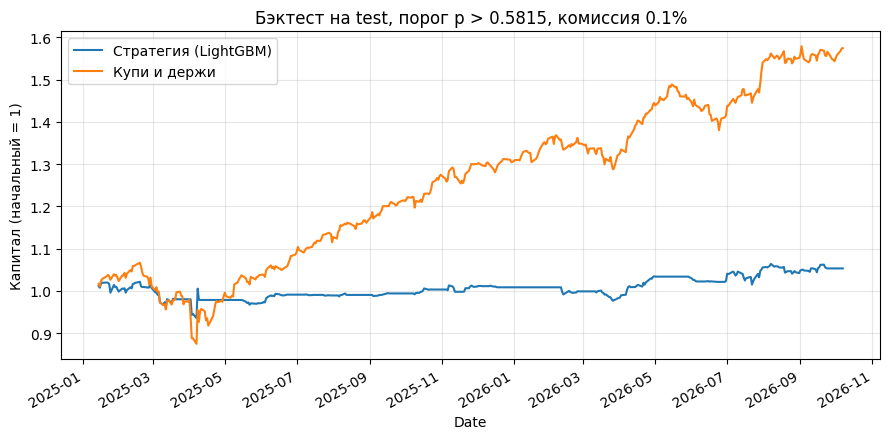

In [4]:
strat, bh, pos = backtest(test, best_thr)

result = pd.DataFrame({
    "Стратегия (LightGBM)": perf(strat),
    "Купи и держи": perf(bh),
}).T
result["Доля времени в позиции"] = [pos.mean().mean(), 1.0]
display(result.round(4))
result.to_csv(f"{PROJECT_DIR}/backtest_test.csv")

plt.figure(figsize=(9, 4.5))
(1 + strat).cumprod().plot(label="Стратегия (LightGBM)")
(1 + bh).cumprod().plot(label="Купи и держи")
plt.title(f"Бэктест на test, порог p > {best_thr}, комиссия 0.1%")
plt.ylabel("Капитал (начальный = 1)"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{PROJECT_DIR}/fig_backtest.png", dpi=150, bbox_inches="tight")
plt.show()

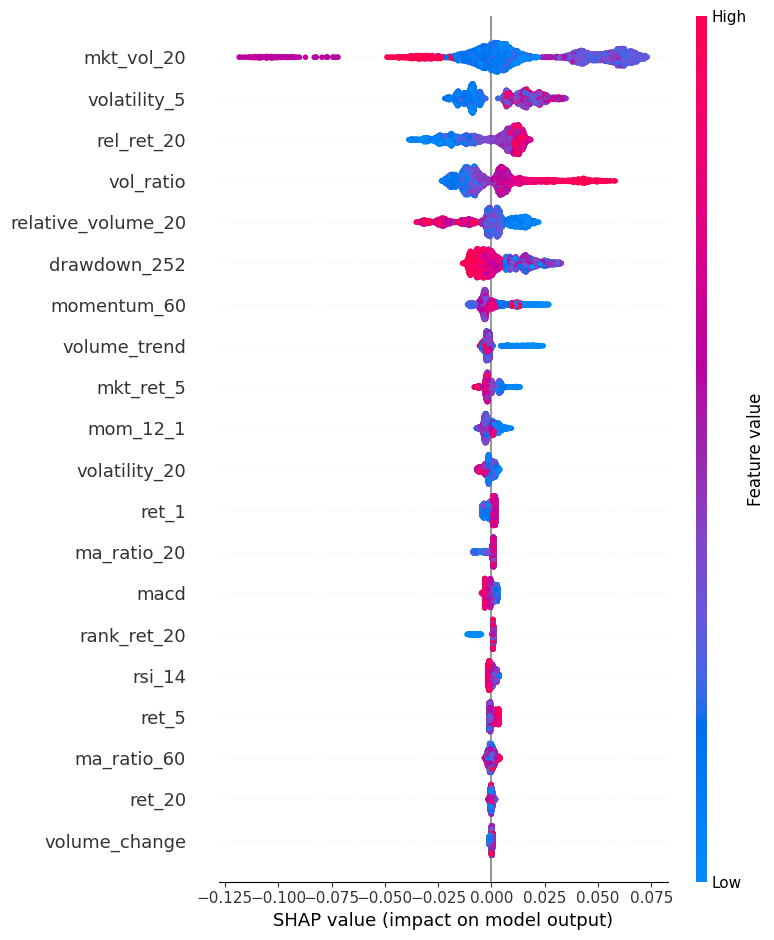

In [5]:
t = test.reset_index(drop=True)
X_test = t[F]

explainer = shap.TreeExplainer(best_model)
exp = explainer(X_test)
if exp.values.ndim == 3:           # в некоторых версиях shap — по классу
    exp = exp[:, :, 1]

shap.summary_plot(exp.values, X_test, show=False)
plt.tight_layout()
plt.savefig(f"{PROJECT_DIR}/fig_shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()


1. Самый уверенный сигнал «покупать» (ошибка): JPM, 2025-02-24, p = 0.606, факт: падение


,Значение признака,Вклад SHAP
mkt_vol_20,0.0082,0.0679
vol_ratio,1.5727,0.0581
volatility_5,0.0215,0.0325
relative_volume_20,1.6224,-0.0103
rel_ret_20,-0.0122,0.0062


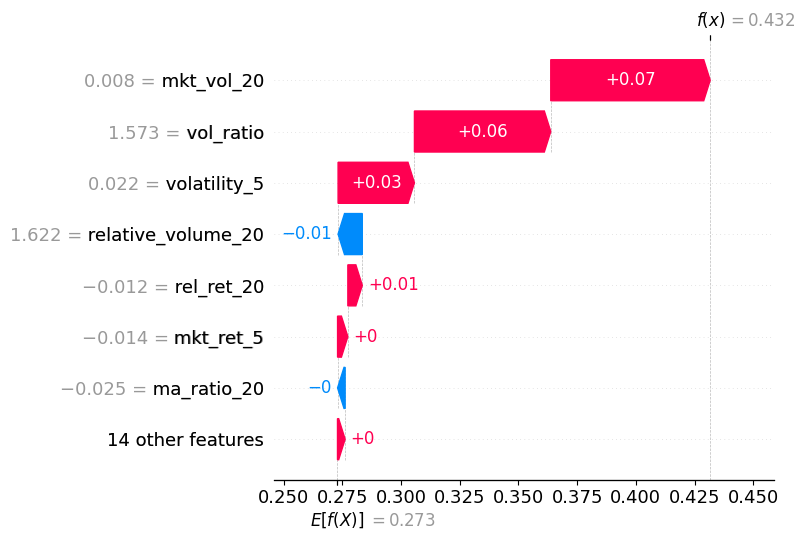


2. Самый уверенный сигнал «не покупать»: KO, 2025-05-15, p = 0.531, факт: падение


,Значение признака,Вклад SHAP
mkt_vol_20,0.0126,-0.0924
rel_ret_20,-0.1174,-0.0169
vol_ratio,0.7586,-0.0094
volatility_5,0.0076,-0.0064
mom_12_1,0.1795,-0.0058


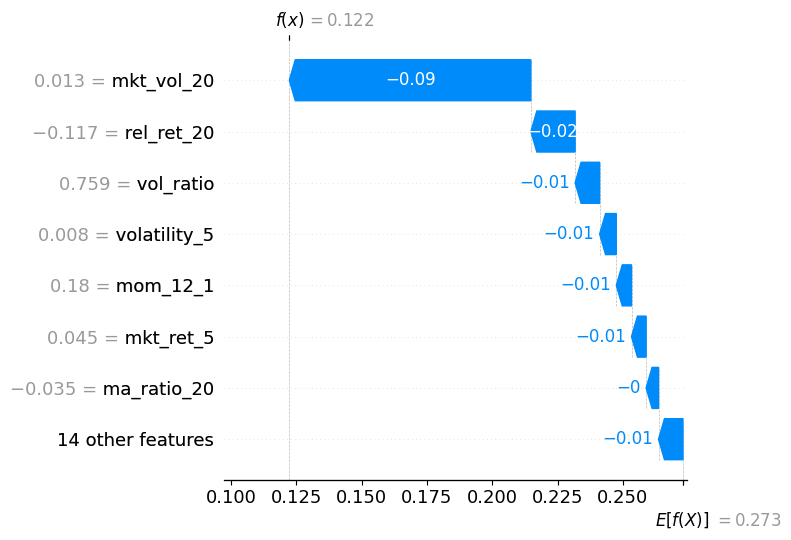


3. Уверенная покупка, оказавшаяся верной: XOM, 2026-08-12, p = 0.606, факт: рост


,Значение признака,Вклад SHAP
mkt_vol_20,0.0085,0.0655
vol_ratio,1.5828,0.0517
volatility_5,0.0248,0.0266
rel_ret_20,0.0416,0.0109
macd,0.0209,-0.0027


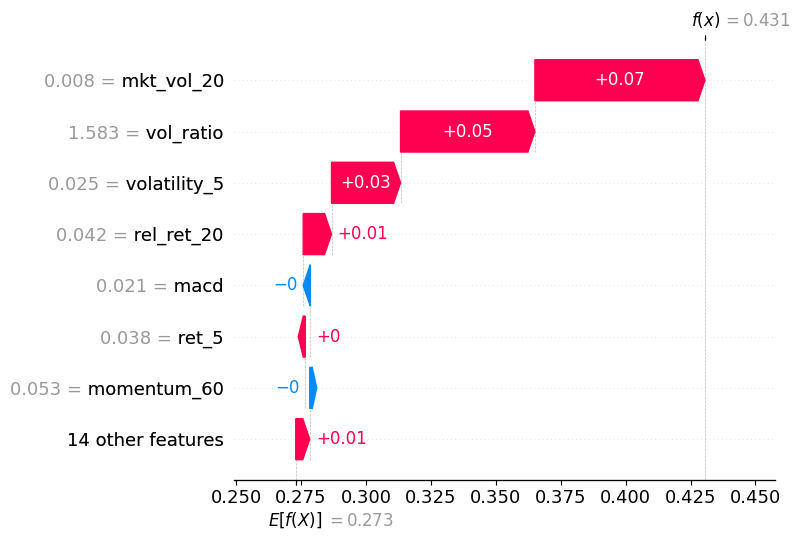

In [15]:
right = t[(t["p"] > best_thr) & (t["target"] == 1)]
cases = {
    "1. Самый уверенный сигнал «покупать» (ошибка)": t["p"].idxmax(),
    "2. Самый уверенный сигнал «не покупать»": t["p"].idxmin(),
    "3. Уверенная покупка, оказавшаяся верной": right["p"].idxmax(),
}

for name, i in cases.items():
    row = t.loc[i]
    print(f"\n{name}: {row['Ticker']}, {row['Date'].date()}, "
          f"p = {row['p']:.3f}, факт: {'рост' if row['target']==1 else 'падение'}")
    contrib = pd.Series(exp.values[i], index=F)
    top = contrib.reindex(contrib.abs().sort_values(ascending=False).index[:5])
    display(pd.DataFrame({"Значение признака": X_test.loc[i, top.index].round(4),
                          "Вклад SHAP": top.round(4)}))
    shap.plots.waterfall(exp[i], max_display=8, show=False)
    plt.tight_layout()
    plt.savefig(f"{PROJECT_DIR}/fig_shap_case{list(cases).index(name)+1}.png",
                dpi=150, bbox_inches="tight")
    plt.show()

In [14]:
def psi(expected, actual, bins=10):
    expected, actual = np.asarray(expected), np.asarray(actual)
    cuts = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    cuts[0], cuts[-1] = -np.inf, np.inf
    e = np.histogram(expected, cuts)[0] / len(expected) + 1e-6
    a = np.histogram(actual, cuts)[0] / len(actual) + 1e-6
    return np.sum((a - e) * np.log(a / e))

imp = pd.Series(best_model.booster_.feature_importance(importance_type="gain"),
                index=F).sort_values(ascending=False)
top5 = list(imp.index[:5])

psi_table = pd.DataFrame(
    [{"Переменная": "Скор модели (p)", "PSI": psi(train["p"], test["p"])}] +
    [{"Переменная": f, "PSI": psi(train[f], test[f])} for f in top5]
)
psi_table["Вывод"] = np.select(
    [psi_table["PSI"] > 0.25, psi_table["PSI"] > 0.10],
    ["нестабилен (> 0.25)", "умеренный сдвиг"], default="стабилен")
display(psi_table.round(4))
psi_table.to_csv(f"{PROJECT_DIR}/psi.csv", index=False)

,Переменная,PSI,Вывод
0,Скор модели (p),0.1653,умеренный сдвиг
1,mkt_vol_20,0.8728,нестабилен (> 0.25)
2,vol_ratio,0.0053,стабилен
3,rel_ret_20,0.0366,стабилен
4,volatility_5,0.1071,умеренный сдвиг
5,relative_volume_20,0.0078,стабилен
